# FSRCNN Evaluation
Mean **PSNR / SSIM / LPIPS / NIQE** for scales x2, x3, x4 (FP32 vs uint8 vs Bicubic)

| Metric | Computed on | Better |
|---|---|---|
| PSNR | Y channel (shaved by scale) | higher |
| SSIM | Y channel (shaved by scale) | higher |
| LPIPS | RGB (SR luma + bicubic chroma) | lower |
| NIQE | RGB (SR luma + bicubic chroma) | lower |

In [1]:
!pip install -q lpips pyiqa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.

## 1. Setup

In [2]:
import kagglehub

path = kagglehub.dataset_download("jesucristo/super-resolution-benchmarks")
print("Path to dataset files:", path)

path = kagglehub.model_download("amiraliabedi97/fsrcnn-nxp/pyTorch/default")
print("Path to model files:", path)

path = kagglehub.dataset_download("joe1995/div2k-dataset")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/jesucristo/super-resolution-benchmarks
Path to model files: /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10
Path to dataset files: /kaggle/input/datasets/joe1995/div2k-dataset


In [3]:
import os, json, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity
import lpips
import pyiqa
import matplotlib.pyplot as plt
from IPython.display import display

DATASETS = {

    'div2k': '/kaggle/input/datasets/joe1995/div2k-dataset/DIV2K_valid_HR/DIV2K_valid_HR'

    
}


CKPT_ROOT = "/kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10"
print(os.listdir(CKPT_ROOT))
OUT_DIR = "/kaggle/working/eval_results"
SCALES = [2, 3, 4]
MODES = ["fp32", "int8"]
INCLUDE_BICUBIC = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(OUT_DIR, exist_ok=True)
print(device)

['fp32_x3.pth', 'fp32_x2.pth', 'int8_x2.pth', 'uint8_x4.pth', 'uint8_x3.pth', 'fp32_x4.pth']
cuda


## 2. Model

In [4]:
class FakeQuant(nn.Module):
    def __init__(self, momentum=0.01):
        super().__init__()
        self.momentum = momentum
        self.register_buffer("min_val", torch.zeros(1))
        self.register_buffer("max_val", torch.zeros(1))
        self.register_buffer("initialized", torch.zeros(1))

    def qparams(self):
        scale = (self.max_val - self.min_val).clamp(min=1e-8) / 255.0
        zp = torch.round(-self.min_val / scale).clamp(0, 255).to(torch.int32)
        return scale, zp

    def forward(self, x):
        if self.training:
            with torch.no_grad():
                bmin = x.detach().min().reshape(1).clamp(max=0.0)
                bmax = x.detach().max().reshape(1).clamp(min=0.0)
                init = self.initialized > 0.5
                m = self.momentum
                self.min_val.copy_(torch.where(init, (1 - m) * self.min_val + m * bmin, bmin))
                self.max_val.copy_(torch.where(init, (1 - m) * self.max_val + m * bmax, bmax))
                self.initialized.fill_(1.0)
        scale, zp = self.qparams()
        return torch.fake_quantize_per_tensor_affine(x, scale, zp, 0, 255)


def fq_weight(w):
    with torch.no_grad():
        mn = w.min().clamp(max=0.0)
        mx = w.max().clamp(min=0.0)
        scale = ((mx - mn).clamp(min=1e-8) / 255.0).reshape(1)
        zp = torch.round(-mn / scale.squeeze()).clamp(0, 255).to(torch.int32).reshape(1)
    return torch.fake_quantize_per_tensor_affine(w, scale, zp, 0, 255)


class QConv2d(nn.Conv2d):
    def forward(self, x):
        return F.conv2d(x, fq_weight(self.weight), self.bias, self.stride, self.padding)


class QConvTranspose2d(nn.ConvTranspose2d):
    def forward(self, x):
        return F.conv_transpose2d(x, fq_weight(self.weight), self.bias, self.stride,
                                  self.padding, self.output_padding)


class FSRCNN(nn.Module):
    def __init__(self, scale, d=56, s=12, m=4, quant=False):
        super().__init__()
        C = QConv2d if quant else nn.Conv2d
        CT = QConvTranspose2d if quant else nn.ConvTranspose2d
        Q = FakeQuant if quant else nn.Identity
        L = [Q(), C(1, d, 5, padding=2), nn.PReLU(d), Q(),
             C(d, s, 1), nn.PReLU(s), Q()]
        for _ in range(m):
            L += [C(s, s, 3, padding=1), nn.PReLU(s), Q()]
        L += [C(s, d, 1), nn.PReLU(d), Q(),
              CT(d, 1, 9, stride=scale, padding=4, output_padding=scale - 1), Q()]
        self.body = nn.Sequential(*L)

    def forward(self, x):
        return self.body(x)


def find_ckpt(mode, scale):
    names = [f"{mode}_x{scale}.pth"]
    if mode in ("int8", "uint8"):
        names += [f"{m}_x{scale}.pth" for m in ("int8", "uint8")]
    for n in names:
        p = os.path.join(CKPT_ROOT, n)
        if os.path.exists(p):
            return p
    return None


def load_model(mode, scale):
    path = find_ckpt(mode, scale)
    if path is None:
        print(f"missing checkpoint: {mode} x{scale}")
        return None
    ckpt = torch.load(path, map_location="cpu")
    state = ckpt["model"] if isinstance(ckpt, dict) and "model" in ckpt else ckpt
    state = {(k[7:] if k.startswith("module.") else k): v for k, v in state.items()}
    net = FSRCNN(scale, quant=(mode in ("int8", "uint8")))
    net.load_state_dict(state)
    print(f"loaded {path}")
    return net.to(device).eval()


models = {(m, s): load_model(m, s) for s in SCALES for m in MODES}

loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/fp32_x2.pth
loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/int8_x2.pth
loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/fp32_x3.pth
loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/uint8_x3.pth
loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/fp32_x4.pth
loaded /kaggle/input/models/amiraliabedi97/fsrcnn-nxp/pytorch/default/10/uint8_x4.pth


## 3. Data and metrics

In [5]:
def list_images(folder):
    exts = (".png", ".jpg", ".jpeg", ".bmp")
    return [os.path.join(folder, f) for f in sorted(os.listdir(folder)) if f.lower().endswith(exts)]


def rgb_to_ycbcr(a):
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    y = 16.0 + (65.481 * r + 128.553 * g + 24.966 * b) / 255.0
    cb = 128.0 + (-37.797 * r - 74.203 * g + 112.0 * b) / 255.0
    cr = 128.0 + (112.0 * r - 93.786 * g - 18.214 * b) / 255.0
    return y, cb, cr


def ycbcr_to_rgb(y, cb, cr):
    y, cb, cr = y - 16.0, cb - 128.0, cr - 128.0
    r = 1.164383 * y + 1.596027 * cr
    g = 1.164383 * y - 0.391762 * cb - 0.812968 * cr
    b = 1.164383 * y + 2.017232 * cb
    return np.clip(np.round(np.stack([r, g, b], axis=-1)), 0, 255).astype(np.uint8)


def resize(arr, size, resample=Image.BICUBIC):
    return np.array(Image.fromarray(arr).resize(size, resample))


def prepare(path, scale):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    w, h = w - w % scale, h - h % scale
    img = img.crop((0, 0, w, h))
    rgb = np.asarray(img, dtype=np.float32)
    y, cb, cr = rgb_to_ycbcr(rgb)
    hr_y = np.clip(np.round(y), 0, 255).astype(np.uint8)
    lr_size = (w // scale, h // scale)
    lr_y = resize(hr_y, lr_size)
    lr_cb = resize(cb.astype(np.float32), lr_size)
    lr_cr = resize(cr.astype(np.float32), lr_size)
    return {
        "hr_rgb": np.array(img),
        "hr_y": hr_y,
        "lr_y": lr_y,
        "cb_up": resize(lr_cb, (w, h)),
        "cr_up": resize(lr_cr, (w, h)),
        "size": (w, h),
    }


@torch.no_grad()
def super_resolve(net, lr_y):
    x = torch.from_numpy(lr_y)[None, None].to(device).float() / 255.0
    out = net(x).clamp(0, 1)
    return torch.round(out * 255).squeeze().cpu().numpy().astype(np.uint8)


lpips_fn = lpips.LPIPS(net="alex", verbose=False).to(device).eval()
niqe_fn = pyiqa.create_metric("niqe", device=device)


def to_tensor(rgb_u8):
    return torch.from_numpy(rgb_u8).permute(2, 0, 1)[None].float().div(255.0).to(device)


@torch.no_grad()
def compute_metrics(sr_y, d, scale):
    s = scale
    a = sr_y[s:-s, s:-s].astype(np.float64)
    b = d["hr_y"][s:-s, s:-s].astype(np.float64)
    mse = np.mean((a - b) ** 2)
    psnr = 10 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    ssim = structural_similarity(a, b, data_range=255, gaussian_weights=True,
                                 sigma=1.5, use_sample_covariance=False)
    sr_rgb = ycbcr_to_rgb(sr_y.astype(np.float32), d["cb_up"], d["cr_up"])
    t_sr, t_hr = to_tensor(sr_rgb), to_tensor(d["hr_rgb"])
    lp = lpips_fn(t_sr * 2 - 1, t_hr * 2 - 1).item()
    return {"PSNR": psnr, "SSIM": ssim, "LPIPS": lp}

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 202MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 13.8MB/s]


## 4. Run evaluation

In [6]:
records = []

for ds_name, ds_dir in DATASETS.items():
    if not ds_dir:
        continue
    files = list_images(ds_dir)
    for scale in SCALES:
        for p in tqdm(files, desc=f"{ds_name} x{scale}"):
            d = prepare(p, scale)
            w, h = d["size"]
            outputs = {}
            if INCLUDE_BICUBIC:
                outputs["Bicubic"] = resize(d["lr_y"], (w, h))
            for mode in MODES:
                net = models[(mode, scale)]
                if net is not None:
                    outputs["FSRCNN-" + mode] = super_resolve(net, d["lr_y"])
            for name, sr_y in outputs.items():
                m = compute_metrics(sr_y, d, scale)
                records.append({"dataset": ds_name, "scale": scale, "method": name,
                                "image": os.path.basename(p), **m})

df = pd.DataFrame(records)
assert len(df) > 0
df.to_csv(os.path.join(OUT_DIR, "per_image_metrics.csv"), index=False)
print(len(df), "rows")

div2k x2:   0%|          | 0/100 [00:00<?, ?it/s]

div2k x3:   0%|          | 0/100 [00:00<?, ?it/s]

div2k x4:   0%|          | 0/100 [00:00<?, ?it/s]

900 rows


## 5. Results

In [7]:
METRICS = ["PSNR", "SSIM", "LPIPS"]

summary = df.groupby(["dataset", "scale", "method"])[METRICS].mean()
summary.round(4).to_csv(os.path.join(OUT_DIR, "summary_per_dataset.csv"))

display(summary.style
        .format({"PSNR": "{:.3f}", "SSIM": "{:.4f}", "LPIPS": "{:.4f}"})
        .background_gradient(cmap="Blues", subset=["PSNR", "SSIM"])
        .background_gradient(cmap="Greens_r", subset=["LPIPS"])
        .set_caption("Mean metrics per dataset, scale and method"))

In [8]:
overall = df.groupby(["scale", "method"])[METRICS].mean()
overall.round(4).to_csv(os.path.join(OUT_DIR, "summary_overall.csv"))

display(overall.style
        .format({"PSNR": "{:.2f}", "SSIM": "{:.4f}", "LPIPS": "{:.4f}"})
        .background_gradient(cmap="Blues", subset=["PSNR", "SSIM"])
        .background_gradient(cmap="Greens_r", subset=["LPIPS"])
        .set_caption("Mean metrics over all datasets"))

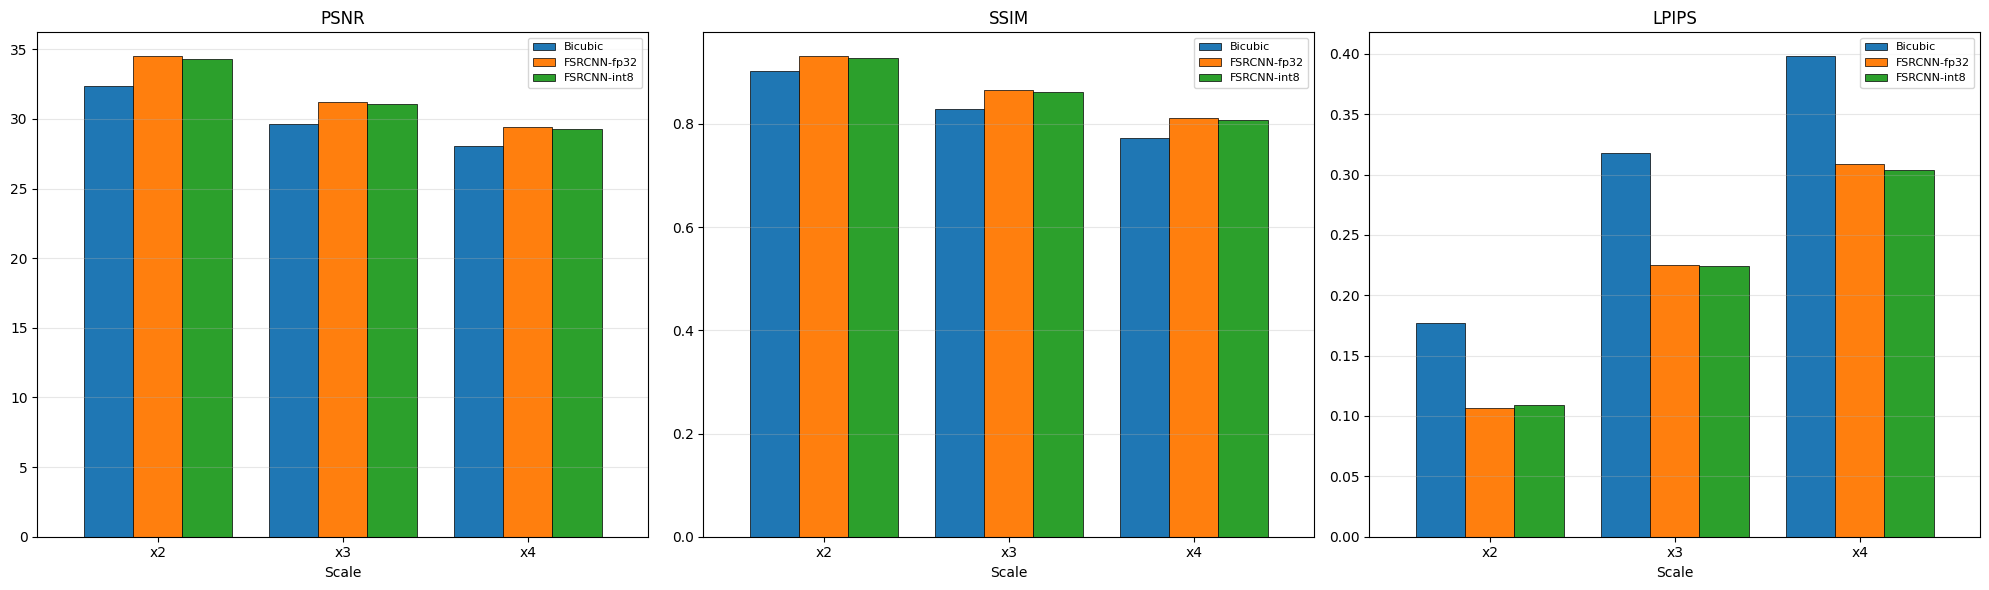

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, metric in zip(axes, METRICS):
    pv = overall[metric].unstack("method")
    pv.plot.bar(ax=ax, rot=0, width=0.8, edgecolor="black", linewidth=0.5)
    ax.set_title(metric)
    ax.set_xlabel("Scale")
    ax.set_xticklabels([f"x{s}" for s in pv.index])
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "metrics_overview.png"), dpi=200, bbox_inches="tight")
plt.show()

## 6. Patch-based inference (overlapping patches + blending)
Instead of running the network on the full image, the LR Y image is cut into equal `PATCH_SIZE x PATCH_SIZE` patches with a given `stride` (stride < patch size gives overlap). Each patch is upscaled, pasted at its HR position, and overlapping regions are merged by a weighted average:

| Blend | Weight inside a patch |
|---|---|
| `average` | uniform (simple average) |
| `linear` | triangular, peaks at the patch centre |
| `hann` | raised cosine, peaks at the centre |
| `gaussian` | Gaussian, peaks at the centre (`GAUSS_SIGMA`) |

PSNR / SSIM / LPIPS are then computed on the **full reconstructed image**, with the same functions as section 3, and compared with full-image inference and bicubic.

Results are shown as a table and as line plots (PSNR / SSIM / LPIPS vs overlap %, one line per blend, dashed line = full-image inference).

patch div2k x2:   0%|          | 0/100 [00:00<?, ?it/s]

patch div2k x3:   0%|          | 0/100 [00:00<?, ?it/s]

patch div2k x4:   0%|          | 0/100 [00:00<?, ?it/s]

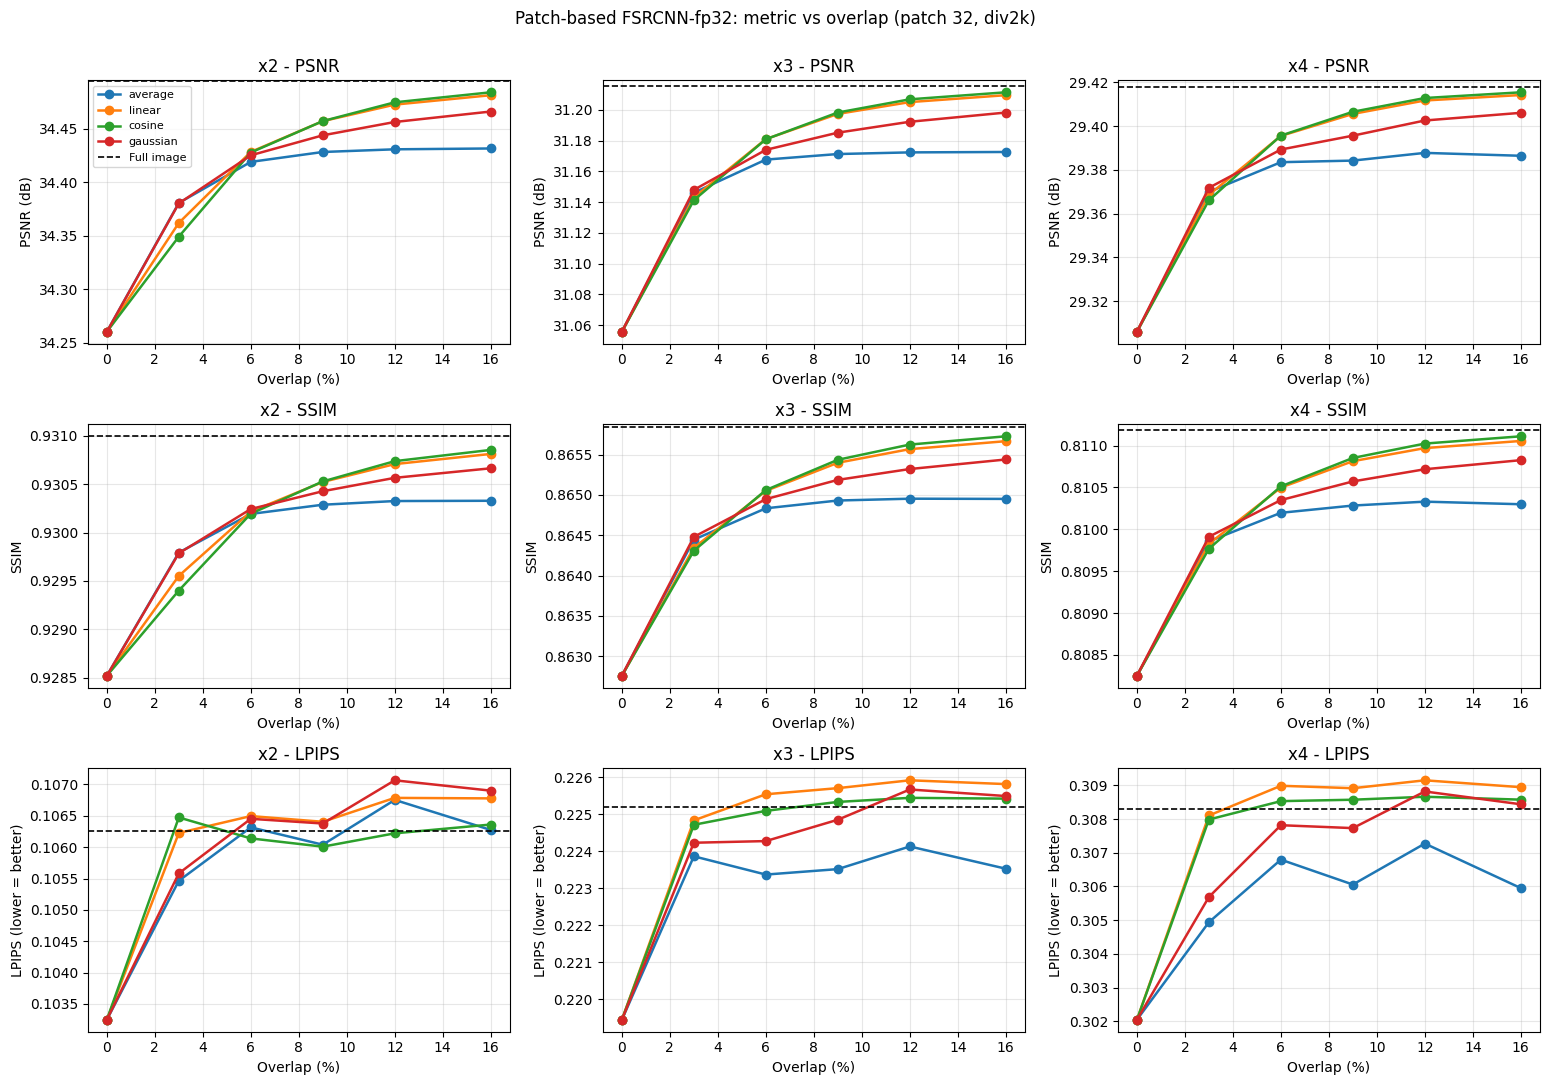

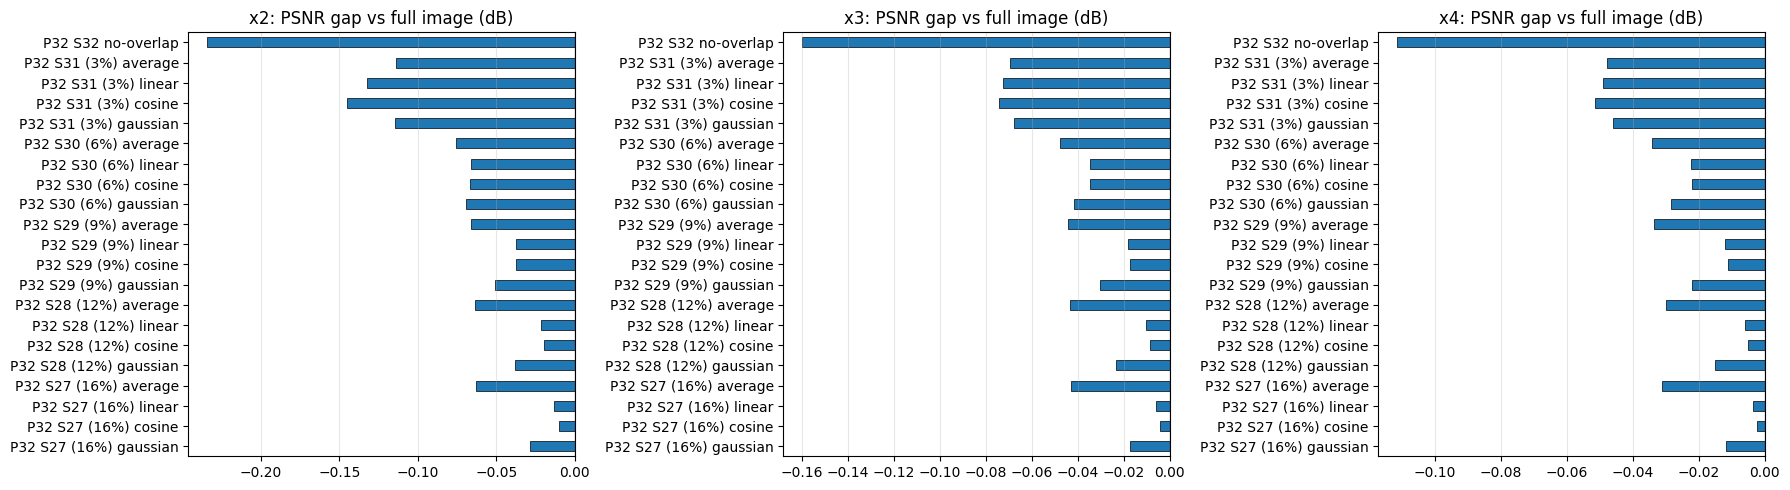

In [10]:
import matplotlib.pyplot as plt

PATCH_DATASETS = DATASETS.keys()
PATCH_MODES    = ["fp32"]
PATCH_SCALES   = SCALES
PATCH_SIZE     = 32
PATCH_STRIDES  = [32, 31, 30, 29, 28, 27]
BLEND_METHODS  = ["average", "linear", "cosine", "gaussian"]
GAUSS_SIGMA    = 0.5
PATCH_BATCH    = 64


def patch_positions(n, p, s):
    """Top-left coordinates along one axis; the last patch is snapped to the border."""
    if n <= p:
        return [0]
    pos = list(range(0, n - p + 1, s))
    if pos[-1] != n - p:
        pos.append(n - p)
    return pos


def blend_window(ph, pw, method, sigma=GAUSS_SIGMA, eps=1e-3):
    """2D weight map (HR patch size). Weights are normalised later by the sum of weights."""
    def profile(L):
        t = (np.arange(L) + 0.5) / L * 2 - 1          # -1 .. 1 across the patch
        if method == "average":
            w = np.ones(L)
        elif method == "linear":
            w = 1 - np.abs(t)
        elif method == "cosine":
            w = 0.5 * (1 + np.cos(np.pi * t))
        elif method == "gaussian":
            w = np.exp(-t ** 2 / (2 * sigma ** 2))
        else:
            raise ValueError(method)
        return np.maximum(w, eps)
    return np.outer(profile(ph), profile(pw)).astype(np.float32)


@torch.no_grad()
def sr_patches(net, lr_y, patch, stride, batch=PATCH_BATCH):
    """Cut the LR Y image into overlapping patches and upscale them (float output, 0..255)."""
    H, W = lr_y.shape
    ph, pw = min(patch, H), min(patch, W)
    coords = [(y, x) for y in patch_positions(H, ph, stride)
                     for x in patch_positions(W, pw, stride)]
    img = torch.from_numpy(lr_y).float().div(255.0)
    outs = []
    for i in range(0, len(coords), batch):
        b = torch.stack([img[y:y + ph, x:x + pw] for y, x in coords[i:i + batch]])[:, None].to(device)
        outs.append((net(b).clamp(0, 1) * 255).squeeze(1).cpu().numpy())
    return coords, np.concatenate(outs)


def blend_patches(coords, patches, hr_shape, scale, method):
    """Paste HR patches at (y*scale, x*scale) and combine overlaps by weighted average."""
    acc = np.zeros(hr_shape, np.float32)
    wsum = np.zeros(hr_shape, np.float32)
    ph, pw = patches.shape[1:]
    w = blend_window(ph, pw, method)
    for (y, x), p in zip(coords, patches):
        ys, xs = y * scale, x * scale
        acc[ys:ys + ph, xs:xs + pw] += p * w
        wsum[ys:ys + ph, xs:xs + pw] += w
    return np.clip(np.round(acc / wsum), 0, 255).astype(np.uint8)


patch_records = []
for ds_name in PATCH_DATASETS:
    files = list_images(DATASETS[ds_name])
    for scale in PATCH_SCALES:
        for p in tqdm(files, desc=f"patch {ds_name} x{scale}"):
            d = prepare(p, scale)
            w, h = d["size"]
            hr_shape = (h, w)
            outputs = {"Bicubic": (resize(d["lr_y"], (w, h)), dict(mode="-", blend="Bicubic", stride=0, overlap=0))}

            for mode in PATCH_MODES:
                net = models[(mode, scale)]
                if net is None:
                    continue
                outputs[f"{mode} | Full image"] = (super_resolve(net, d["lr_y"]),
                                                   dict(mode=mode, blend="Full image", stride=0, overlap=0))
                for stride in PATCH_STRIDES:
                    coords, patches = sr_patches(net, d["lr_y"], PATCH_SIZE, stride)
                    overlap = max(0, round(100 * (1 - stride / PATCH_SIZE)))
                    if stride >= PATCH_SIZE:                        
                        outputs[f"{mode} | P{PATCH_SIZE} S{stride} no-overlap"] = (
                            blend_patches(coords, patches, hr_shape, scale, "average"),
                            dict(mode=mode, blend="no-overlap", stride=stride, overlap=0))
                        continue
                    for method in BLEND_METHODS:
                        outputs[f"{mode} | P{PATCH_SIZE} S{stride} ({overlap}%) {method}"] = (
                            blend_patches(coords, patches, hr_shape, scale, method),
                            dict(mode=mode, blend=method, stride=stride, overlap=overlap))

            for name, (sr_y, meta) in outputs.items():
                m = compute_metrics(sr_y, d, scale)       # same Y-channel PSNR/SSIM + RGB LPIPS as before
                patch_records.append({"dataset": ds_name, "scale": scale, "method": name,
                                      "image": os.path.basename(p), **meta, **m})

pdf = pd.DataFrame(patch_records)
pdf.to_csv(os.path.join(OUT_DIR, "patch_per_image_metrics.csv"), index=False)

patch_summary = pdf.groupby(["scale", "method"], sort=False)[METRICS].mean()
patch_summary.round(4).to_csv(os.path.join(OUT_DIR, "patch_summary_overall.csv"))
display(patch_summary.style
        .format({"PSNR": "{:.3f}", "SSIM": "{:.4f}", "LPIPS": "{:.4f}"})
        .background_gradient(cmap="Blues", subset=["PSNR", "SSIM"])
        .background_gradient(cmap="Greens_r", subset=["LPIPS"])
        .set_caption(f"Patch-based inference ({', '.join(PATCH_DATASETS)}) - mean metrics"))


line_tbl = pdf.groupby(["scale", "mode", "blend", "overlap"])[METRICS].mean().reset_index()
YLABEL = {"PSNR": "PSNR (dB)", "SSIM": "SSIM", "LPIPS": "LPIPS (lower = better)"}

for mode in PATCH_MODES:
    fig, axes = plt.subplots(len(METRICS), len(PATCH_SCALES),
                             figsize=(5.2 * len(PATCH_SCALES), 3.6 * len(METRICS)), squeeze=False)
    for j, scale in enumerate(PATCH_SCALES):
        t = line_tbl[(line_tbl["scale"] == scale) & (line_tbl["mode"] == mode)]
        if t.empty:
            continue
        base = t[t["blend"] == "no-overlap"]
        full = t[t["blend"] == "Full image"]
        for i, metric in enumerate(METRICS):
            ax = axes[i, j]
            for method in BLEND_METHODS:
                r = t[t["blend"] == method].sort_values("overlap")
                xs, ys = r["overlap"].tolist(), r[metric].tolist()
                if len(base):                                        # start every line at the no-overlap point
                    xs, ys = [0] + xs, [base[metric].iloc[0]] + ys
                ax.plot(xs, ys, marker="o", lw=1.8, label=method)
            if len(full):
                ax.axhline(full[metric].iloc[0], color="k", ls="--", lw=1.2, label="Full image")
            ax.set_xlabel("Overlap (%)")
            ax.set_ylabel(YLABEL[metric])
            ax.set_title(f"x{scale} - {metric}")
            ax.grid(alpha=0.3)
            if i == 0 and j == 0:
                ax.legend(fontsize=8)
    fig.suptitle(f"Patch-based FSRCNN-{mode}: metric vs overlap (patch {PATCH_SIZE}, {', '.join(PATCH_DATASETS)})", y=1.0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"patch_lines_{mode}.png"), dpi=200, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(1, len(PATCH_SCALES), figsize=(6 * len(PATCH_SCALES), 5), squeeze=False)
for ax, scale in zip(axes[0], PATCH_SCALES):
    s = patch_summary.loc[scale]
    for mode in PATCH_MODES:
        ref = s.loc[f"{mode} | Full image", "PSNR"]
        rows = [k for k in s.index if k.startswith(f"{mode} | P")]
        gap = (s.loc[rows, "PSNR"] - ref)
        gap.index = [k.split(" | ")[1] for k in rows]
        gap.plot.barh(ax=ax, edgecolor="black", linewidth=0.5, label=mode)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"x{scale}: PSNR gap vs full image (dB)")
    ax.grid(axis="x", alpha=0.3)
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "patch_psnr_gap.png"), dpi=200, bbox_inches="tight")
plt.show()